# PRCP-1018: Bike Rental Prediction

## Project Overview

This project focuses on analyzing bike rental data and predicting the daily
bike rental count based on environmental and seasonal settings.

### Objectives

1. Perform complete data analysis on the bike rental dataset.
2. Understand the relationship between environmental, seasonal and rental features.
3. Perform data preprocessing and feature engineering.
4. Build multiple machine learning models.
5. Compare the performance of different models.
6. Select a suitable model for production.
7. Analyze the challenges faced during the project and the techniques used to overcome them.

## Problem Statement

The objective of this project is to predict the daily total number of
bike rentals (`cnt`) using environmental and seasonal information.

The dataset contains information such as season, year, month, weather
condition, temperature, humidity, windspeed, working day, and bike rental counts.

In [2]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Regression models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Evaluation metrics
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

In [3]:
# Load the daily bike rental dataset

df = pd.read_csv(r"C:\Users\pavan\Downloads\bike+sharing+dataset\day.csv")

# Display first 5 rows
df

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
726,727,2012-12-27,1,1,12,0,4,1,2,0.254167,0.226642,0.652917,0.350133,247,1867,2114
727,728,2012-12-28,1,1,12,0,5,1,2,0.253333,0.255046,0.590000,0.155471,644,2451,3095
728,729,2012-12-29,1,1,12,0,6,0,2,0.253333,0.242400,0.752917,0.124383,159,1182,1341
729,730,2012-12-30,1,1,12,0,0,0,1,0.255833,0.231700,0.483333,0.350754,364,1432,1796


In [4]:
df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [5]:
# Check number of rows and columns

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 731
Number of columns: 16


In [6]:
# Display all column names

print(df.columns.tolist())

['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']


In [7]:
# Get information about the dataset

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [8]:
# Statistical summary of numerical columns

df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [9]:
# Check missing values

df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [10]:
# Check duplicate records

df.duplicated().sum()

np.int64(0)

In [11]:
# Convert date column to datetime

df['dteday'] = pd.to_datetime(df['dteday'])

# Check data types again
df.dtypes

instant                int64
dteday        datetime64[ns]
season                 int64
yr                     int64
mnth                   int64
holiday                int64
weekday                int64
workingday             int64
weathersit             int64
temp                 float64
atemp                float64
hum                  float64
windspeed            float64
casual                 int64
registered             int64
cnt                    int64
dtype: object

In [12]:
# Check target variable

print("Minimum rental count:", df['cnt'].min())
print("Maximum rental count:", df['cnt'].max())
print("Average rental count:", df['cnt'].mean())

Minimum rental count: 22
Maximum rental count: 8714
Average rental count: 4504.3488372093025


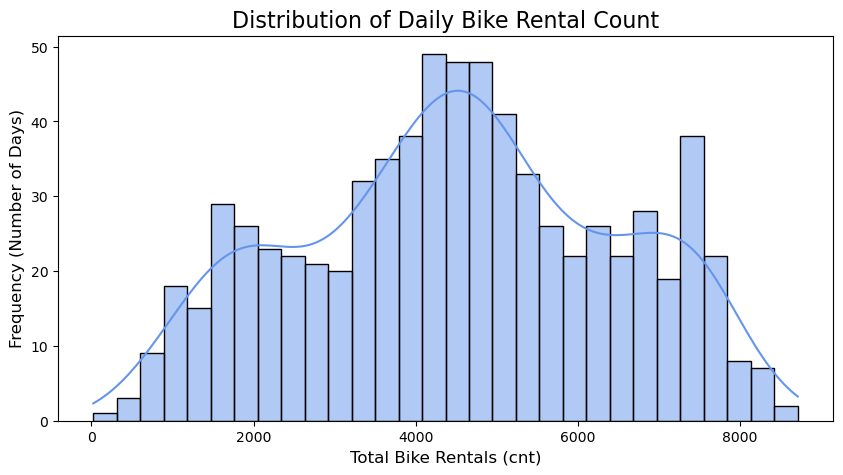

In [13]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['cnt'],
    bins=30,
    kde=True,
    color='cornflowerblue',
    edgecolor='black'
)

plt.title("Distribution of Daily Bike Rental Count", fontsize=16)
plt.xlabel("Total Bike Rentals (cnt)", fontsize=12)
plt.ylabel("Frequency (Number of Days)", fontsize=12)

plt.show()

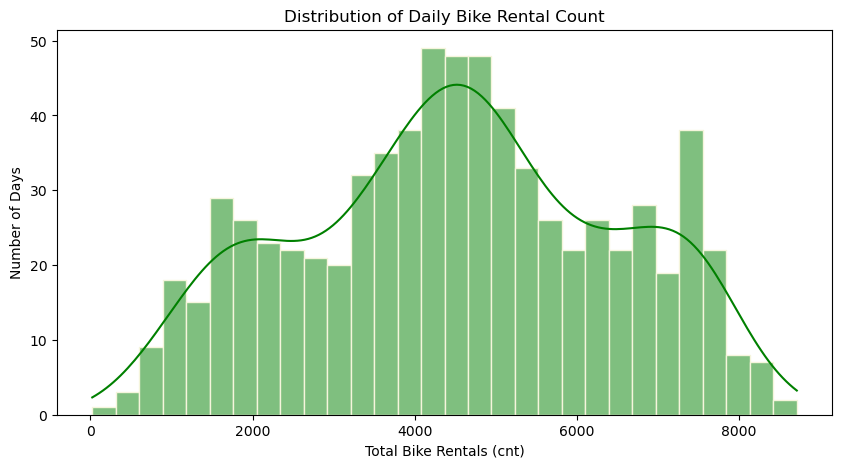

In [15]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['cnt'],
    bins=30,
    kde=True,
    color='green',
    edgecolor='beige'
)

plt.title("Distribution of Daily Bike Rental Count")
plt.xlabel("Total Bike Rentals (cnt)")
plt.ylabel("Number of Days")

plt.show()

In [16]:
df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [17]:
# Create a copy of the original dataset

df_clean = df.copy()

print("Dataset copied successfully!")

Dataset copied successfully!


In [18]:
# Check missing values in each column

missing_values = df_clean.isnull().sum()

print(missing_values)

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


In [19]:
# Display only columns having missing values

missing_values = df_clean.isnull().sum()

missing_values[missing_values > 0]

Series([], dtype: int64)

In [20]:
# Display only columns having missing values

missing_values = df_clean.isnull().sum()

missing_values[missing_values > 0]

Series([], dtype: int64)

In [21]:
# Check duplicate rows

duplicate_count = df_clean.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [22]:
# Convert dteday column to datetime format

df_clean['dteday'] = pd.to_datetime(df_clean['dteday'])

print(df_clean['dteday'].dtype)

datetime64[ns]


In [23]:
# Check the date range

print("Start Date:", df_clean['dteday'].min())
print("End Date:", df_clean['dteday'].max())

Start Date: 2011-01-01 00:00:00
End Date: 2012-12-31 00:00:00


In [24]:
# Check unique values of categorical columns

categorical_columns = [
    'season',
    'yr',
    'mnth',
    'holiday',
    'weekday',
    'workingday',
    'weathersit'
]

for column in categorical_columns:
    print("\n", column)
    print(df_clean[column].unique())


 season
[1 2 3 4]

 yr
[0 1]

 mnth
[ 1  2  3  4  5  6  7  8  9 10 11 12]

 holiday
[0 1]

 weekday
[6 0 1 2 3 4 5]

 workingday
[0 1]

 weathersit
[2 1 3]


In [25]:
# Check numerical columns

numerical_columns = [
    'temp',
    'atemp',
    'hum',
    'windspeed',
    'casual',
    'registered',
    'cnt'
]

df_clean[numerical_columns].describe()

,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [26]:
# Check for negative values in important numerical columns

for column in numerical_columns:
    negative_count = (df_clean[column] < 0).sum()
    print(column, ":", negative_count)

temp : 0
atemp : 0
hum : 0
windspeed : 0
casual : 0
registered : 0
cnt : 0


In [27]:
# Check duplicate dates

duplicate_dates = df_clean['dteday'].duplicated().sum()

print("Number of duplicate dates:", duplicate_dates)

Number of duplicate dates: 0


In [28]:
# Final check after cleaning

print("Dataset shape:", df_clean.shape)
print("\nMissing values:")
print(df_clean.isnull().sum())

print("\nDuplicate rows:", df_clean.duplicated().sum())

Dataset shape: (731, 16)

Missing values:
instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Duplicate rows: 0


## Data Cleaning Summary

- The `dteday` column was converted into datetime format.
- Missing values were checked for all columns.
- Duplicate rows were identified and checked.
- Unique values of categorical variables were examined.
- Numerical variables were checked for descriptive statistics and negative values.
- The date range of the dataset was verified.
- The cleaned dataset is now ready for exploratory data analysis (EDA).

In [29]:
season_avg = df_clean.groupby('season')['cnt'].mean()

print(season_avg)

season
1    2604.132597
2    4992.331522
3    5644.303191
4    4728.162921
Name: cnt, dtype: float64


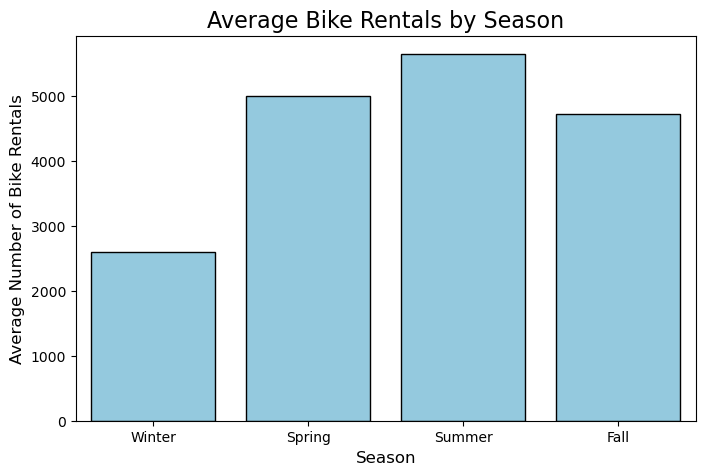

In [30]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=season_avg.index,
    y=season_avg.values,
    color='skyblue',
    edgecolor='black'
)

plt.title("Average Bike Rentals by Season", fontsize=16)
plt.xlabel("Season", fontsize=12)
plt.ylabel("Average Number of Bike Rentals", fontsize=12)

plt.xticks(
    ticks=[0, 1, 2, 3],
    labels=['Winter', 'Spring', 'Summer', 'Fall']
)

plt.show()

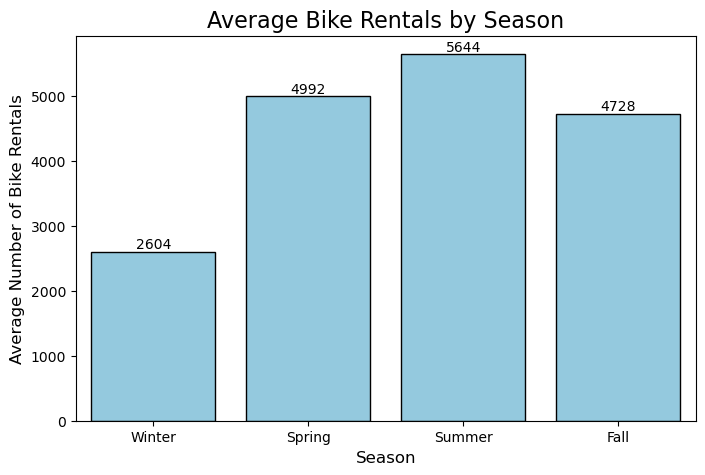

In [31]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=season_avg.index,
    y=season_avg.values,
    color='skyblue',
    edgecolor='black'
)

plt.title("Average Bike Rentals by Season", fontsize=16)
plt.xlabel("Season", fontsize=12)
plt.ylabel("Average Number of Bike Rentals", fontsize=12)

plt.xticks(
    ticks=[0, 1, 2, 3],
    labels=['Winter', 'Spring', 'Summer', 'Fall']
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f')

plt.show()

## EDA 2: Average Bike Rentals by Season

* This bar chart compares the average number of bike rentals across the
four seasons.

* The analysis helps us understand whether seasonal conditions are
associated with differences in daily bike rental demand.

In [32]:
weather_avg = df_clean.groupby('weathersit')['cnt'].mean()

print(weather_avg)

weathersit
1    4876.786177
2    4035.862348
3    1803.285714
Name: cnt, dtype: float64


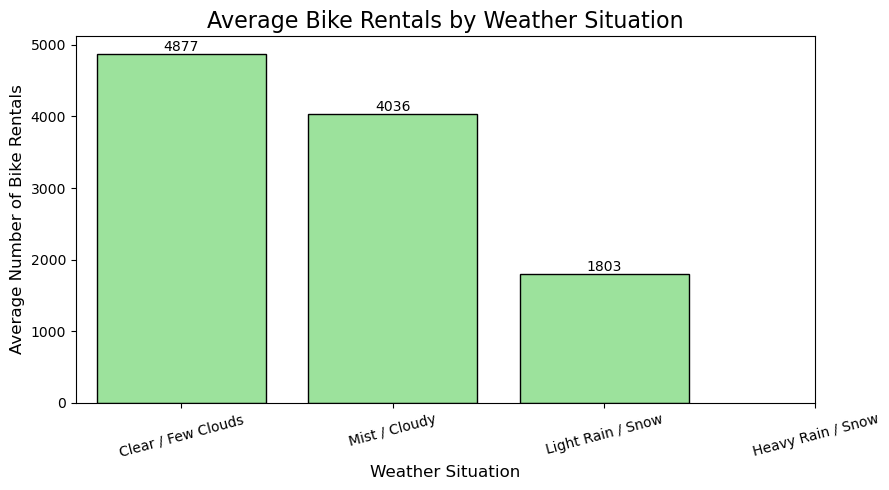

In [33]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=weather_avg.index,
    y=weather_avg.values,
    color='lightgreen',
    edgecolor='black'
)

plt.title("Average Bike Rentals by Weather Situation", fontsize=16)
plt.xlabel("Weather Situation", fontsize=12)
plt.ylabel("Average Number of Bike Rentals", fontsize=12)

plt.xticks(
    ticks=[0, 1, 2, 3],
    labels=[
        'Clear / Few Clouds',
        'Mist / Cloudy',
        'Light Rain / Snow',
        'Heavy Rain / Snow'
    ],
    rotation=15
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f')

plt.tight_layout()
plt.show()

## EDA 3: Weather Situation vs Average Bike Rentals

* This bar chart compares the average number of daily bike rentals across
different weather situations.

* The analysis helps us understand how weather conditions are associated
with bike rental demand. The weather categories are based on the
`weathersit` attribute provided in the project dataset description.

In [34]:
month_avg = df_clean.groupby('mnth')['cnt'].mean()

print(month_avg)

mnth
1     2176.338710
2     2655.298246
3     3692.258065
4     4484.900000
5     5349.774194
6     5772.366667
7     5563.677419
8     5664.419355
9     5766.516667
10    5199.225806
11    4247.183333
12    3403.806452
Name: cnt, dtype: float64


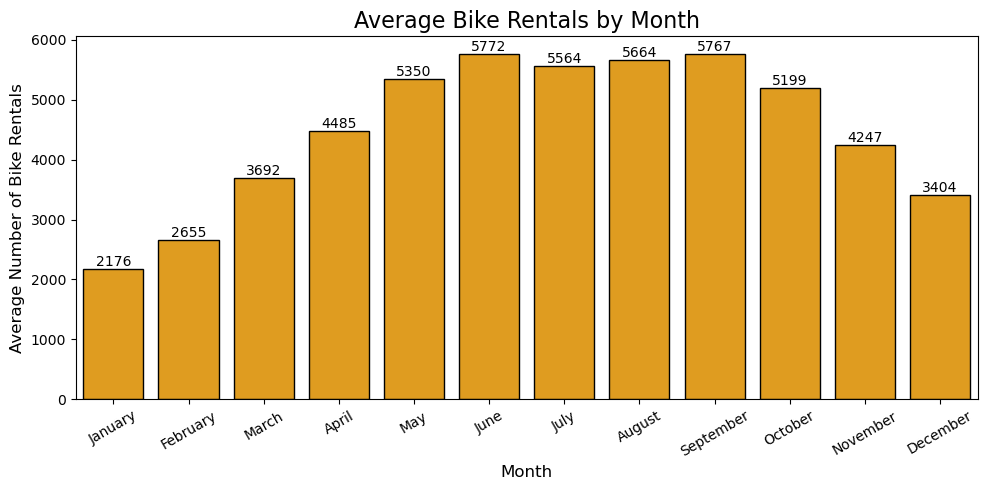

In [35]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=month_avg.index,
    y=month_avg.values,
    color='orange',
    edgecolor='black'
)

plt.title("Average Bike Rentals by Month", fontsize=16)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Average Number of Bike Rentals", fontsize=12)

plt.xticks(
    ticks=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11],
    labels=[
        'January', 'February', 'March', 'April',
        'May', 'June', 'July', 'August',
        'September', 'October', 'November', 'December'
    ],
    rotation=30
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f')

plt.tight_layout()
plt.show()

## EDA 4: Month vs Average Bike Rentals

* This bar chart compares the average number of daily bike rentals across
different months of the year.

* The analysis helps us understand how monthly patterns are associated
with bike rental demand. It can also help identify months with relatively
higher or lower average rental activity.

In [36]:
workingday_avg = df_clean.groupby('workingday')['cnt'].mean()

print(workingday_avg)

workingday
0    4330.168831
1    4584.820000
Name: cnt, dtype: float64


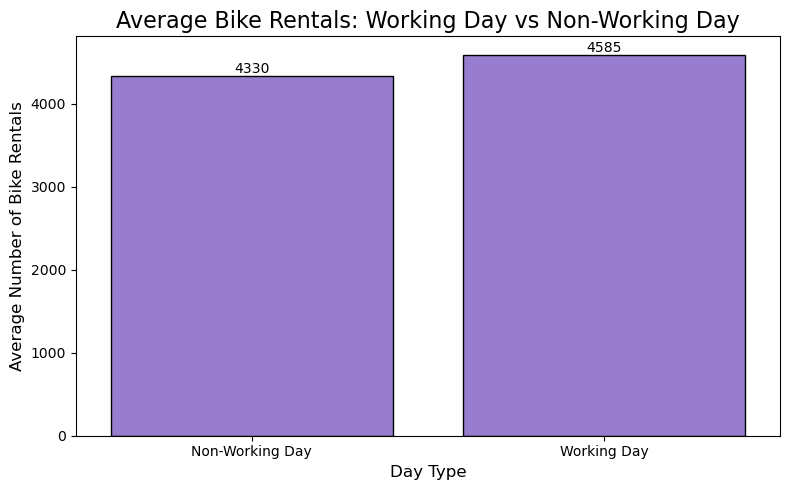

In [37]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=workingday_avg.index,
    y=workingday_avg.values,
    color='mediumpurple',
    edgecolor='black'
)

plt.title("Average Bike Rentals: Working Day vs Non-Working Day", fontsize=16)
plt.xlabel("Day Type", fontsize=12)
plt.ylabel("Average Number of Bike Rentals", fontsize=12)

plt.xticks(
    ticks=[0, 1],
    labels=['Non-Working Day', 'Working Day']
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f')

plt.tight_layout()
plt.show()

## EDA 5: Working Day vs Average Bike Rentals

* This bar chart compares the average number of daily bike rentals
between working days and non-working days.

* The analysis helps us understand whether the type of day is associated
with differences in bike rental demand.

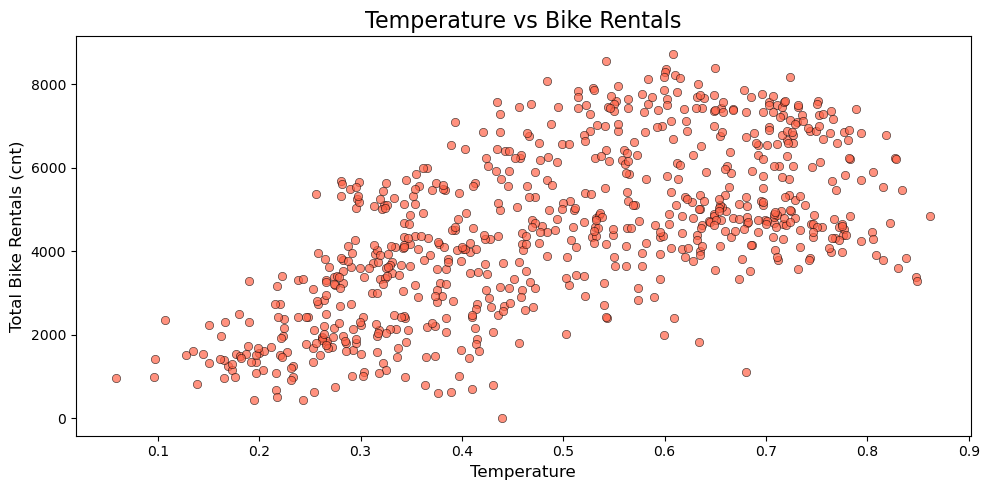

In [39]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    x='temp',
    y='cnt',
    data=df_clean,
    color='tomato',
    edgecolor='black',
    alpha=0.7
)

plt.title("Temperature vs Bike Rentals", fontsize=16)
plt.xlabel("Temperature", fontsize=12)
plt.ylabel("Total Bike Rentals (cnt)", fontsize=12)

plt.tight_layout()
plt.show()

## EDA 6: Temperature vs Bike Rentals

* This scatter plot shows the relationship between temperature and
the total number of daily bike rentals.

* The analysis helps us understand whether changes in temperature are
associated with changes in bike rental demand. The distribution of
points can also indicate whether the relationship appears to be
positive, negative, or weak.

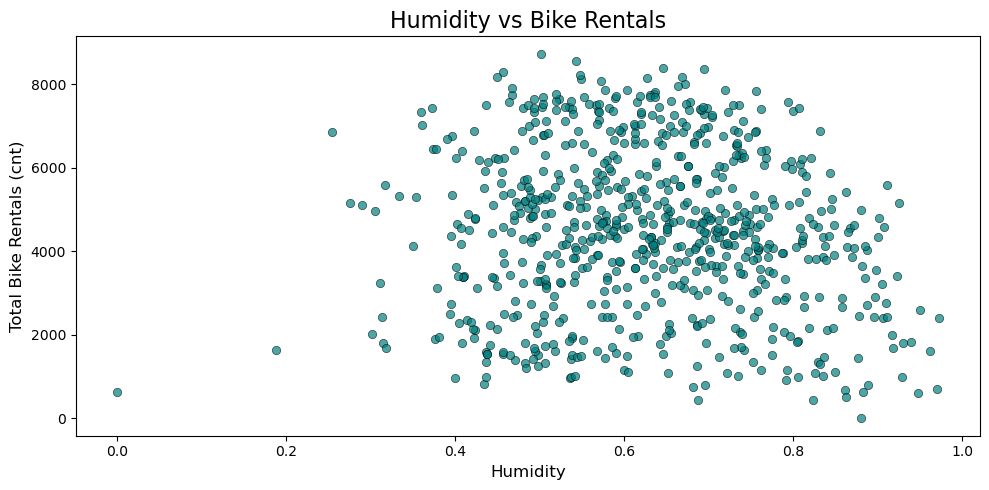

In [40]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    x='hum',
    y='cnt',
    data=df_clean,
    color='teal',
    edgecolor='black',
    alpha=0.7
)

plt.title("Humidity vs Bike Rentals", fontsize=16)
plt.xlabel("Humidity", fontsize=12)
plt.ylabel("Total Bike Rentals (cnt)", fontsize=12)

plt.tight_layout()
plt.show()

## EDA 7: Humidity vs Bike Rentals

* This scatter plot shows the relationship between humidity and
the total number of daily bike rentals.

* The analysis helps us understand whether changes in humidity are
associated with changes in bike rental demand. The pattern of the
points can indicate whether the relationship appears to be
positive, negative, or weak.

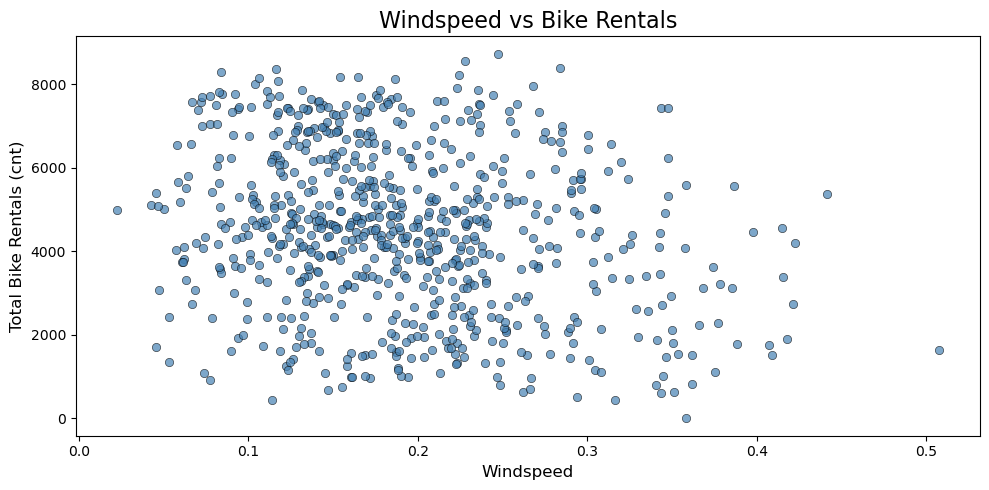

In [41]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    x='windspeed',
    y='cnt',
    data=df_clean,
    color='steelblue',
    edgecolor='black',
    alpha=0.7
)

plt.title("Windspeed vs Bike Rentals", fontsize=16)
plt.xlabel("Windspeed", fontsize=12)
plt.ylabel("Total Bike Rentals (cnt)", fontsize=12)

plt.tight_layout()
plt.show()

## EDA 8: Windspeed vs Bike Rentals

* This scatter plot shows the relationship between windspeed and
the total number of daily bike rentals.

* The analysis helps us understand whether changes in windspeed are
associated with changes in bike rental demand. The distribution
of the points can indicate whether the relationship appears to
be positive, negative, or weak.

In [42]:
year_avg = df_clean.groupby('yr')['cnt'].mean()

print(year_avg)

yr
0    3405.761644
1    5599.934426
Name: cnt, dtype: float64


plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=year_avg.index,
    y=year_avg.values,
    color='cornflowerblue',
    edgecolor='black'
)

plt.title("Average Bike Rentals by Year", fontsize=16)
plt.xlabel("Year", fontsize=12)
plt.ylabel("Average Number of Bike Rentals", fontsize=12)

plt.xticks(
    ticks=[0, 1],
    labels=['2011', '2012']
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f')

plt.tight_layout()
plt.show()

## EDA 9: Year vs Average Bike Rentals

* This bar chart compares the average number of daily bike rentals
between the two years in the dataset.

* The analysis helps us understand how the average bike rental demand
changed from 2011 to 2012.

In [44]:
season_avg = df_clean.groupby('season')['cnt'].mean()

print(season_avg)

season
1    2604.132597
2    4992.331522
3    5644.303191
4    4728.162921
Name: cnt, dtype: float64


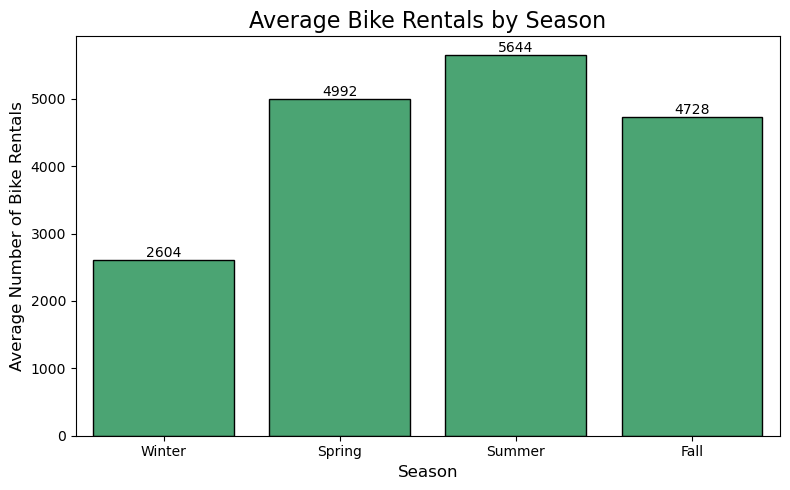

In [45]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=season_avg.index,
    y=season_avg.values,
    color='mediumseagreen',
    edgecolor='black'
)

plt.title("Average Bike Rentals by Season", fontsize=16)
plt.xlabel("Season", fontsize=12)
plt.ylabel("Average Number of Bike Rentals", fontsize=12)

plt.xticks(
    ticks=[0, 1, 2, 3],
    labels=['Winter', 'Spring', 'Summer', 'Fall']
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f')

plt.tight_layout()
plt.show()

## EDA 10: Season vs Average Bike Rentals

* This bar chart compares the average number of daily bike rentals
across the four seasons: Winter, Spring, Summer, and Fall.

* The analysis helps us understand how seasonal conditions are associated
with changes in bike rental demand. The actual bar heights can be used
to identify the seasons with relatively higher or lower average rentals.

In [46]:
user_avg = {
    'Casual Users': df_clean['casual'].mean(),
    'Registered Users': df_clean['registered'].mean()
}

print(user_avg)

{'Casual Users': np.float64(848.1764705882352), 'Registered Users': np.float64(3656.172366621067)}


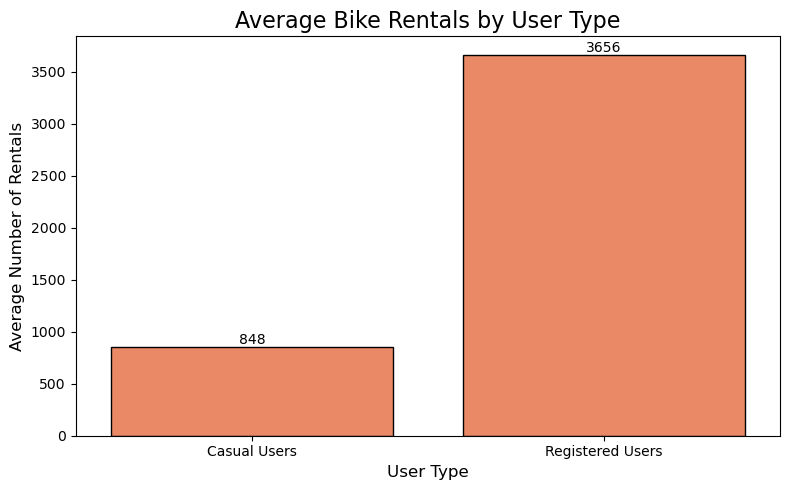

In [47]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=list(user_avg.keys()),
    y=list(user_avg.values()),
    color='coral',
    edgecolor='black'
)

plt.title("Average Bike Rentals by User Type", fontsize=16)
plt.xlabel("User Type", fontsize=12)
plt.ylabel("Average Number of Rentals", fontsize=12)

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f')

plt.tight_layout()
plt.show()

## EDA 11: Casual vs Registered Users

* This bar chart compares the average number of daily rentals
made by casual and registered users.

* The analysis helps us understand the contribution of each user
type to overall bike rental demand.

In [48]:
numerical_data = df_clean[
    ['temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']
]

correlation_matrix = numerical_data.corr()

print(correlation_matrix)

                temp     atemp       hum  windspeed    casual  registered  \
temp        1.000000  0.991702  0.126963  -0.157944  0.543285    0.540012   
atemp       0.991702  1.000000  0.139988  -0.183643  0.543864    0.544192   
hum         0.126963  0.139988  1.000000  -0.248489 -0.077008   -0.091089   
windspeed  -0.157944 -0.183643 -0.248489   1.000000 -0.167613   -0.217449   
casual      0.543285  0.543864 -0.077008  -0.167613  1.000000    0.395282   
registered  0.540012  0.544192 -0.091089  -0.217449  0.395282    1.000000   
cnt         0.627494  0.631066 -0.100659  -0.234545  0.672804    0.945517   

                 cnt  
temp        0.627494  
atemp       0.631066  
hum        -0.100659  
windspeed  -0.234545  
casual      0.672804  
registered  0.945517  
cnt         1.000000  


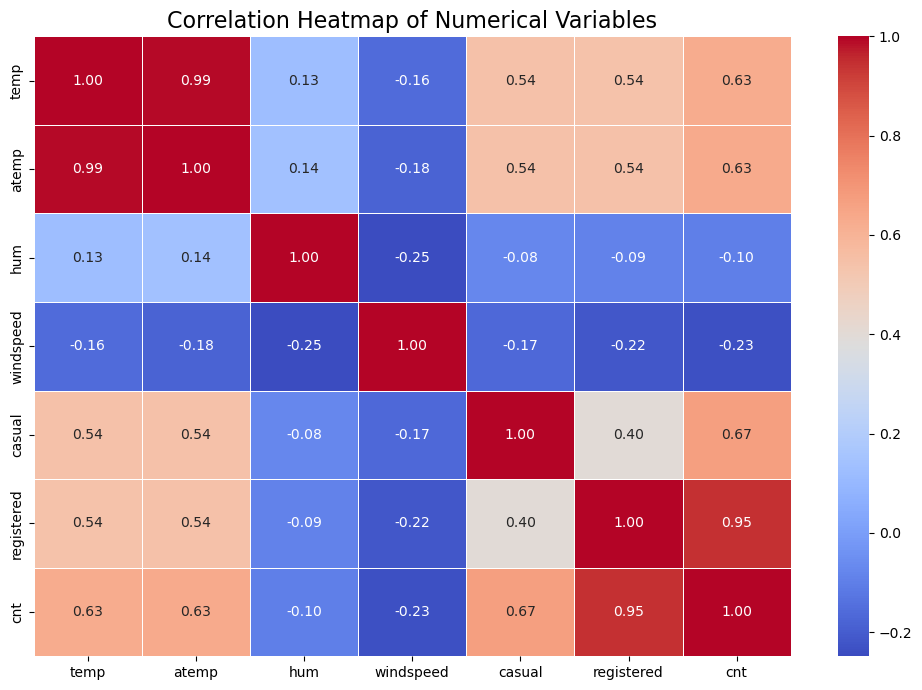

In [49]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Variables", fontsize=16)

plt.tight_layout()
plt.show()

## EDA 12: Correlation Heatmap of Numerical Variables

* The correlation heatmap shows the strength and direction of the
linear relationship between numerical variables.

* Values close to +1 indicate a strong positive relationship, values
close to -1 indicate a strong negative relationship, and values
close to 0 indicate a weak linear relationship.

* This analysis helps identify potentially important variables for
predicting the total number of bike rentals (`cnt`).

In [50]:
# Select input features (X)
X = df_clean.drop(columns=['instant', 'dteday', 'casual', 'registered', 'cnt'])

# Target variable (y)
y = df_clean['cnt']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (731, 11)
Target shape: (731,)


In [51]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (584, 11)
X_test shape: (147, 11)


In [53]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Feature Selection and Train/Test Split

* In this step, relevant input features were selected to predict the
target variable `cnt`, which represents the total number of bike rentals.

* Columns such as `instant` and `dteday` were removed as they do not
contribute directly to prediction. The `casual` and `registered`
columns were also excluded to prevent data leakage, since their sum
forms the target variable.

* The dataset was then split into training and testing sets using an
80:20 ratio. Feature scaling was applied using StandardScaler to
normalize the feature values for better model performance.

In [54]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()

lr_model.fit(X_train_scaled, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [55]:
y_pred_lr = lr_model.predict(X_test_scaled)

print("First 10 Predictions:")
print(y_pred_lr[:10])

First 10 Predictions:
[6220.41661215 1571.60576321 3043.96702808 4307.202484   6765.65907166
 7231.53610596  774.90414671 2139.60660149 7112.74560525 6458.99216879]


In [56]:
mae_lr = mean_absolute_error(y_test, y_pred_lr)
mse_lr = mean_squared_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mse_lr)
r2_lr = r2_score(y_test, y_pred_lr)

print("Linear Regression Performance")
print("--------------------------------")
print("MAE  :", mae_lr)
print("MSE  :", mse_lr)
print("RMSE :", rmse_lr)
print("R²   :", r2_lr)

Linear Regression Performance
--------------------------------
MAE  : 617.3930656443374
MSE  : 691035.0082022655
RMSE : 831.2851545662688
R²   : 0.8276670090367211


## Model 1: Linear Regression

* Linear Regression was used as the first baseline model to predict
the total number of daily bike rentals (`cnt`).

* The model was trained using the training dataset and evaluated on
the test dataset.

* The following evaluation metrics were used:

- MAE: Mean Absolute Error
- MSE: Mean Squared Error
- RMSE: Root Mean Squared Error
- R²: Coefficient of Determination

* These metrics help measure how accurately the model predicts daily
bike rental demand.

In [58]:
from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(random_state=42)

dt_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [59]:
y_pred_dt = dt_model.predict(X_test)

print("First 10 Predictions:")
print(y_pred_dt[:10])

First 10 Predictions:
[7509. 1450. 3613. 3510. 7525. 7347. 1538. 2808. 6879. 5464.]


In [60]:
mae_dt = mean_absolute_error(y_test, y_pred_dt)
mse_dt = mean_squared_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mse_dt)
r2_dt = r2_score(y_test, y_pred_dt)

print("Decision Tree Performance")
print("--------------------------")
print("MAE  :", mae_dt)
print("MSE  :", mse_dt)
print("RMSE :", rmse_dt)
print("R²   :", r2_dt)

Decision Tree Performance
--------------------------
MAE  : 662.8027210884354
MSE  : 968219.2653061225
RMSE : 983.9813338199676
R²   : 0.7585417237651239


## Model 2: Decision Tree Regressor

* Decision Tree Regressor was used as the second machine learning model
to predict the total number of daily bike rentals (`cnt`).

* The model splits the data into different branches based on the input
features and learns patterns that help predict bike rental demand.

* The model was evaluated using MAE, MSE, RMSE, and R² metrics.

* Lower MAE, MSE, and RMSE values indicate smaller prediction errors,
while a higher R² value indicates better model performance.

In [61]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [62]:
y_pred_rf = rf_model.predict(X_test)

print("First 10 Predictions:")
print(y_pred_rf[:10])

First 10 Predictions:
[6762.08 1545.98 3410.46 4761.3  7493.35 7340.87 1486.33 2342.3  7207.01
 6468.18]


In [63]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Performance")
print("--------------------------")
print("MAE  :", mae_rf)
print("MSE  :", mse_rf)
print("RMSE :", rmse_rf)
print("R²   :", r2_rf)

Random Forest Performance
--------------------------
MAE  : 429.958299319728
MSE  : 458446.9475870749
RMSE : 677.0871048743101
R²   : 0.8856707218333267


## Model 3: Random Forest Regressor

* Random Forest Regressor is an ensemble learning model that combines
multiple decision trees to make predictions.

* It was used to predict the total number of daily bike rentals (`cnt`).

* The model was evaluated using MAE, MSE, RMSE, and R² metrics.

* Random Forest can capture non-linear relationships between the input
features and bike rental demand.

In [64]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(
    n_estimators=100,
    random_state=42
)

gb_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [65]:
y_pred_gb = gb_model.predict(X_test)

print("First 10 Predictions:")
print(y_pred_gb[:10])

First 10 Predictions:
[6733.94865834 1514.78037566 3502.71147196 4512.59284939 7403.49733184
 7160.85110644 1556.39755631 2051.43343679 7266.54194286 6679.33009682]


In [66]:
mae_gb = mean_absolute_error(y_test, y_pred_gb)
mse_gb = mean_squared_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mse_gb)
r2_gb = r2_score(y_test, y_pred_gb)

print("Gradient Boosting Performance")
print("--------------------------------")
print("MAE  :", mae_gb)
print("MSE  :", mse_gb)
print("RMSE :", rmse_gb)
print("R²   :", r2_gb)


Gradient Boosting Performance
--------------------------------
MAE  : 462.77011755459665
MSE  : 438669.7456876681
RMSE : 662.3214821275753
R²   : 0.8906028371614286


## Model 4: Gradient Boosting Regressor

* Gradient Boosting Regressor is an ensemble learning model that
builds multiple decision trees sequentially.

* Each new tree attempts to reduce the errors made by the previous
trees. The model was used to predict the total number of daily
bike rentals (`cnt`).

* The model was evaluated using MAE, MSE, RMSE, and R² metrics.
Gradient Boosting can capture complex and non-linear relationships
between the input features and bike rental demand.

In [67]:
model_comparison = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree Regressor',
        'Random Forest Regressor',
        'Gradient Boosting Regressor'
    ],
    'MAE': [
        mae_lr,
        mae_dt,
        mae_rf,
        mae_gb
    ],
    'MSE': [
        mse_lr,
        mse_dt,
        mse_rf,
        mse_gb
    ],
    'RMSE': [
        rmse_lr,
        rmse_dt,
        rmse_rf,
        rmse_gb
    ],
    'R²': [
        r2_lr,
        r2_dt,
        r2_rf,
        r2_gb
    ]
})

model_comparison

,Model,MAE,MSE,RMSE,R²
0,Linear Regression,617.393066,691035.008202,831.285155,0.827667
1,Decision Tree Regressor,662.802721,968219.265306,983.981334,0.758542
2,Random Forest Regressor,429.958299,458446.947587,677.087105,0.885671
3,Gradient Boosting Regressor,462.770118,438669.745688,662.321482,0.890603


In [68]:
model_comparison.round(2)

,Model,MAE,MSE,RMSE,R²
0,Linear Regression,617.39,691035.01,831.29,0.83
1,Decision Tree Regressor,662.80,968219.27,983.98,0.76
2,Random Forest Regressor,429.96,458446.95,677.09,0.89
3,Gradient Boosting Regressor,462.77,438669.75,662.32,0.89


## Model Comparison

* The performance of the four regression models was compared using
MAE, MSE, RMSE, and R².

* For MAE, MSE, and RMSE, lower values indicate better prediction
performance. For R², a higher value indicates that the model
explains more variation in the target variable.

* The comparison table helps identify the model that provides the
most suitable performance for predicting daily bike rental demand.

In [69]:
# Best model based on highest R²
best_model_row = model_comparison.loc[model_comparison['R²'].idxmax()]

print("Best Model:")
print(best_model_row['Model'])

print("\nPerformance:")
print("MAE  :", round(best_model_row['MAE'], 2))
print("MSE  :", round(best_model_row['MSE'], 2))
print("RMSE :", round(best_model_row['RMSE'], 2))
print("R²   :", round(best_model_row['R²'], 2))

Best Model:
Gradient Boosting Regressor

Performance:
MAE  : 462.77
MSE  : 438669.75
RMSE : 662.32
R²   : 0.89


## Best Production Model

* The four regression models were compared using MAE, MSE, RMSE, and R².

* The model with the highest R² and comparatively lower error metrics
was considered for production use.

* The selected model provides a suitable balance of prediction accuracy
and generalization for predicting daily bike rental demand.

In [70]:
best_model = model_comparison.loc[model_comparison['R²'].idxmax()]

print("Best Production Model:", best_model['Model'])
print("MAE :", round(best_model['MAE'], 2))
print("MSE :", round(best_model['MSE'], 2))
print("RMSE:", round(best_model['RMSE'], 2))
print("R²  :", round(best_model['R²'], 2))

Best Production Model: Gradient Boosting Regressor
MAE : 462.77
MSE : 438669.75
RMSE: 662.32
R²  : 0.89


## Best Production Model

* The best production model was selected based on the highest R² value
among the four regression models.

* The model with the highest R² explains the largest proportion of the
variation in daily bike rental demand among the models tested.

* The selected model was evaluated using MAE, MSE, RMSE, and R². Lower
MAE, MSE, and RMSE indicate smaller prediction errors, while a higher
R² indicates better model performance.

* Therefore, the model with the highest R² was selected as the preferred
production model for predicting daily bike rental demand.

## Challenges Faced

The following challenges were considered during the bike rental
prediction project:

1. Understanding the different environmental, seasonal, and weather-related
   features in the dataset.

2. Checking the dataset for missing values, duplicate records, and
   incorrect data types.

3. Selecting appropriate features for predicting the target variable `cnt`.

4. Avoiding data leakage by excluding `casual` and `registered`, since
   they are components of the total rental count `cnt`.

5. Comparing multiple regression models using MAE, MSE, RMSE, and R².

6. Achieving accurate predictions because bike rental demand can vary
   depending on seasonal, environmental, and weather conditions.

## Final Conclusion

* This project analyzed daily bike rental demand using the Bike Sharing
dataset.

* Exploratory Data Analysis was performed to understand the relationship
between bike rentals and factors such as season, weather situation,
month, working day, temperature, humidity, and windspeed.

* Four regression models were developed and evaluated:

- Linear Regression
- Decision Tree Regressor
- Random Forest Regressor
- Gradient Boosting Regressor

* The models were compared using MAE, MSE, RMSE, and R². The model with
the highest R² value was selected as the preferred production model.

* The analysis demonstrates how machine learning can be used to predict
daily bike rental demand using environmental and seasonal information.